<a href="https://colab.research.google.com/github/FelipeOliveira948/Atividades/blob/main/desafio2/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Desafio 2 de Estatistica Python!**


* Pergunta de negócio:

**R**: Quanto se arrecadam com festivais?

* Coluna numérica de análise:

**R**: Valor

* Decisão que o resultado apoiaria:

**R**: Os festivais de musica estão gerando o valor aguardado? Ou seu custo gera mais prejuizo do que lucro?

#**Célula 01 · Importações**

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

#**Célula 02 · Carregar os arquivos CSV**

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "atracoes"   # ex.: "livros"
NOME_TABELA_FATO = "ingressos_vendidos"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Mounted at /content/drive
Selecione os arquivos CSV (atracoes e ingressos_vendidos). Pode escolher os dois de uma vez:


Saving atracoes.csv to atracoes.csv
Saving ingressos_vendidos.csv to ingressos_vendidos.csv
atracoes.csv -> atracoes.csv
ingressos_vendidos.csv -> ingressos_vendidos.csv
atracoes -> 10100 linhas
ingressos_vendidos -> 55000 linhas


# **Célula 03 · Conhecendo a tabela dimensão**

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10100 linhas e 7 colunas (variáveis)


,atracao_id,nome_artista,genero_musical,edicao_festival,dia_apresentacao,palco,horario_inicio
0,1,Banda Moura,sertanejo,Festival Illo 2025,2025-01-23,eletronico,20:45
1,2,Coletivo Casa Grande,rap,Festival Nobis 2026,2026-04-20,secundario,13:45
2,3,Banda da Rosa,eletronica,Festival Voluptate 2023,2023-05-23,secundario,12:00
3,4,Banda Farias,rap,Festival Iusto 2026,2026-10-11,principal,16:00
4,5,Rodrigues,reggae,Festival Aperiam 2023,2023-04-06,eletronico,12:30


# **Célula 04 · Conhecendo a tabela fato**

In [8]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
df_fato["data_hora_venda"] = pd.to_datetime(df_fato["data_hora_venda"])
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 7 colunas (variáveis)


,venda_id,atracao_id,tipo_ingresso,canal_venda,data_hora_venda,valor,forma_pagamento
0,1,3291,pista,bilheteria_fisica,2022-11-12 17:19:45,122.58,pix
1,2,66,pista_premium,app,2026-04-27 13:42:21,429.29,cartao_credito
2,3,8369,pista,site,2022-11-01 14:04:35,112.52,pix
3,4,8497,pista_premium,site,2021-04-16 12:50:44,459.93,cartao_credito
4,5,9073,pista,app,2020-01-24 15:19:11,190.61,pix


# **Célula 05 · Tipos das colunas**

In [9]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   venda_id         55000 non-null  int64         
 1   atracao_id       55000 non-null  int64         
 2   tipo_ingresso    55000 non-null  object        
 3   canal_venda      55000 non-null  object        
 4   data_hora_venda  55000 non-null  datetime64[ns]
 5   valor            55000 non-null  float64       
 6   forma_pagamento  55000 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 2.9+ MB


# **Célula 06 · Valores ausentes**

In [10]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
venda_id           0
atracao_id         0
tipo_ingresso      0
canal_venda        0
data_hora_venda    0
valor              0
forma_pagamento    0
dtype: int64


# **Célula 07 · Linhas duplicadas**

In [11]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


# **Célula 08 · Chave estrangeira**

In [14]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "atracao_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "atracao_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


**Leitura da conferência**

- (tamanho da tabela fato e se há linhas duplicadas)
**A tabela fato tem 55000 linhas e 7 colunas (variáveis) e 0 duplicações.**

- (se a chave estrangeira bate com a dimensão)
**Foi identificado que a chave estrangeira bate com a dimensão com valor True.**

- (se a coluna de análise tem valores ausentes)
**Foi analisado 0 Valores ausentes.**

- (se há valores ausentes em outras colunas e por que estão vazios: erro ou não)
**Não há valores ausentes.**

# **Célula 09 · Checar a coluna numérica**

In [15]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


# **Célula 10 · Medidas estatísticas**

In [16]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,469.54
Mediana,290.00
Moda,202.98
Desvio padrão,455.12
Variância,207135.74
Mínimo,80.55
Máximo,2975.31
Amplitude,2894.76


Média - mediana: 179.54


- **A média de (coluna) é (valor)**. O custo de cada ingresso é em média 469.54

- **A mediana de (coluna) é (valor)**. A mediana de 290 identifica uma assimetria a direita, como a média é maior está evidente a influencia de valores maiores do que esperado.

- **O desvio padrão de (coluna) é (valor)**. 455.12 mostra uma grande variedade em relação aos valores adquiridos.

- **Decisão final:** Temos uma grande variabilidade de valores altos, o que faz com que a média fique muito tendenciosa, se fosse me apoiar em uma decisão para determinada a venda de igressos usaria como parametro a mediana, uma vez que o valor de média ficou muito influenciado pelos resultados extremos.

# **Célula 11 · Juntar a fato com a dimensão**

In [17]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


# **Célula 12 · Comparar grupos por uma coluna da fato**

In [19]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "edicao_festival"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
edicao_festival,,,,
Festival Sunt 2024,866,509.01,299.77,511.45
Festival Iusto 2026,793,496.13,297.84,477.84
Festival Molestias 2024,795,495.23,300.15,466.82
Festival Excepturi 2019,1167,494.76,297.47,495.03
Festival Quas 2020,1036,489.37,300.83,467.25
Festival Atque 2022,1390,486.45,300.48,467.71
Festival Vel 2021,1023,484.38,289.31,475.98
Festival Quo 2020,2911,482.50,289.44,474.05
Festival Accusantium 2019,765,480.94,292.15,472.20


**Leitura por (coluna de grupo)**

- (grupo com a maior média e se a mediana confirma)

**R**: Festival Sunt 2024 média de 509.01	e a mediana 299.77, não se confirma visto que tem a variedade número contados entre os eventos não pode afirmar que é de fato a maior.

- (grupo com o maior desvio padrão: valores mais espalhados)

**R**: Festival Sunt 2024, tem uma variação de 511.45, mostrando que tem uma variedade muito grande entre os valores analisados para sua média e mediana e isso fica evidente quando analizamos a diferença.

- (se os grupos têm médias parecidas, o que isso diz sobre a categoria)

**R**: Que todos os valores adquiridos na venda dos ingressos desses eventos possuem bastante influencia de valores altos e isso poderia ser indicado pelas categorias de ingressos vendidos ou fatores externos.

# **Célula 13 · Comparar grupos por uma coluna da dimensão**

In [21]:
COLUNA_GRUPO = "genero_musical"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
genero_musical,,,,
forró,3198,482.97,296.58,453.54
reggae,2172,480.63,286.68,473.22
rock,6914,475.49,296.29,457.11
funk,7297,471.63,290.74,452.54
rap,6133,468.80,288.55,455.04
pop,8300,466.93,288.42,456.12
sertanejo,8063,465.43,287.58,454.16
eletronica,8000,464.93,287.61,455.64
mpb,4923,463.99,290.67,448.14


 Qual grupo tem a maior média?

**R**: Forró (482.97)

 A mediana confirma?

**R**: Sim sendo a maior com 296.58	tendo uma diferença de 10 do segundo grupo.


Qual tem o maior desvio padrão (valores mais espalhados)?

**R**: Reggae com 473.22, mostrando a maior variedade de valores do grupo.

# **Célula 14 · Regra do IQR**

In [22]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -347.47 a 1104.52
Outliers: 4653 de 55000 valores
Maiores valores: [2975.31, 2973.81, 2957.95, 2944.94, 2943.81]
Menores valores: [80.55, 81.14, 81.34, 81.77, 81.92]


# **Célula 15 · Medidas com e sem os candidatos a outlier**

In [23]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,469.54,357.40
Mediana,290.00,273.09
Desvio padrão,455.12,238.74


**Leitura e decisão registrada**

- (quantos valores a regra do IQR marcou, a partir de que valor, e como as medidas mudam sem eles)

**R**: Outliers: 4653 de 55000 valores, as medidas mudam ao demonstrar uma variação muito menor, cortando o valor pela metade se compararmos os valores com um desvio padrão de 455.12	para 238.74 sem outliers.

- **Decisão:** (manter, tratar ou excluir) e o porquê

**R**: Tratar os valores, como o objetivo é ter um resultado claro para ver se o lucro do Festival é algo relevante para o patrocinio, é necessário que esses valores sejam tratados para ter uma média e mediana mais limpa e direta.


- **Valores ausentes:** (o que foi feito com eles e por quê)


**R**: Foram usados como uma métrica de melhor hipotese e ignorados para mostrar uma métrica realista de um possivel lucro sem alterações de outliers nas vendas.

# **Célula 16 · Assimetria (skew)**

In [24]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.36


# **Célula 17 · Percentis**

In [25]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     139.1380
0.25     197.0275
0.50     290.0050
0.75     560.0225
0.90    1028.7440
Name: valor, dtype: float64


# **Célula 18 · Quantidade de valores por faixa**

In [26]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor,
"(77.655, 659.502]",43778
"(659.502, 1238.454]",7740
"(1238.454, 1817.406]",1717
"(1817.406, 2396.358]",1331
"(2396.358, 2975.31]",434


**Leitura da distribuição**

- (valor da assimetria e o que ele indica sobre a cauda)

**R**: 2.36 mostra uma assimetria a positiva, mostrando que a cauda está influencia para a direita.

- (percentis: até que valor ficam 75% e 90% dos registros)


**R**: 75% ficam os valores de 560.0225 já os de 90%: 1028.7440.

- (quantos registros estão na primeira faixa e quantos ficam nas faixas mais altas)

**R**: 43778 dos valores ficam na primeira faixa, enquanto apenas 434 ficam nas mais altas.

- Em palavras: (a maioria dos valores fica entre X e Y, e poucos passam de Z)

**R**: A maioria dos registros apresenta valores mais baixos, concentrando-se na primeira faixa, enquanto uma pequena quantidade apresenta valores elevados. Isso demonstra uma distribuição assimétrica positiva, na qual poucos valores muito altos puxam a média para cima.

**Pergunta de negócio:** Quanto se arrecadam com festivais anualmente?

**Evidência 1:** Festival Sunt 2024, ingresso: 866, média de valor vendido	509.01, mediana:	299.77. Esse é o festival com maior lucro encontrado, possuindo um valor mediano de 299.77 arrrecadados por ingressos.

**Evidência 2:** Se tratarmos os valores sem os outlier a média fica 357.40 e a mediana 273.09. Esse é o festival com menor lucro encontrado, possuindo um valor mediano de 273.09 arrecadados por ingressos.

**Recomendação em uma frase:** Se esse lucro entre 273 a 300 reais é o suficiente para custear os gastos com o evento e gerar lucro no final.

**Limites da análise:** Foram ignorados para ter um valor mais adequado para responder a pergunta de negócio. Peguei o valor da mediana para a analise já que não possuem tanta interferencia de valores maiores.

# **Célula 19 · Histograma**


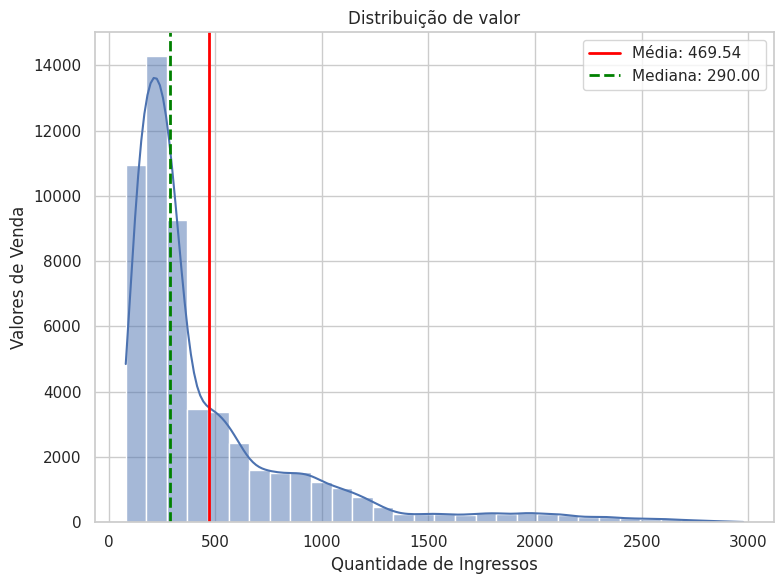

In [30]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Valor da Venda (R$)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Quantidade de Ingressos")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

# **Analisamos que os valores com menores valores são os mais vendidos e aqueles que possuem um alto valor tem uma tendencia de não serem escolhidos na hora da compra.**

# **Célula 20 · Boxplot**

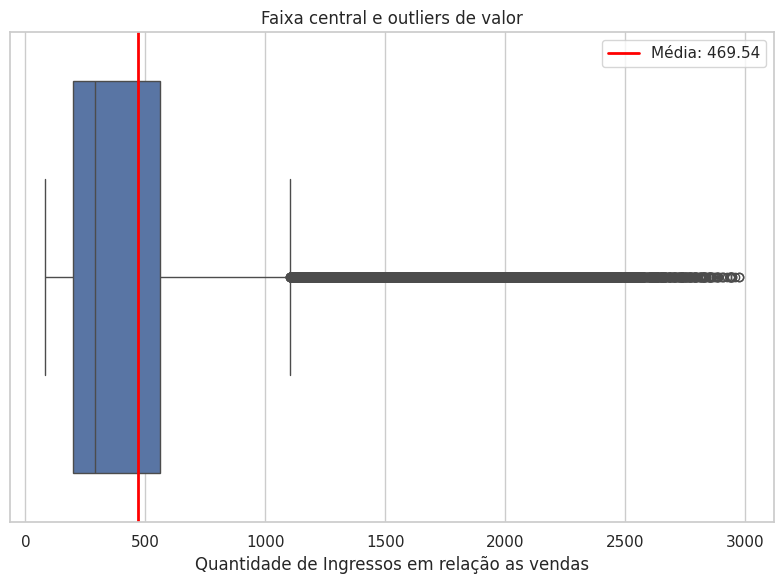

In [32]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Quantidade de Ingressos em relação as vendas")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

**Encontramos que as pessoas costumam em sua maioria pagar em média um valor próximo de 500 reais por ingresso.**